# 🌲 EconoCausal Walkthrough 02: Double Machine Learning (DML) & Heterogeneous Treatment Effects (CATE)

**EconoCausal Production Walkthrough Series**  
*Causal Inference Engine for E-Commerce & Retail Promotion Optimization*

---

## 🎯 Objectives
In this notebook, we implement **Double Machine Learning (Chernozhukov et al., 2018)** to estimate customer-level treatment heterogeneity:
1. **The Double ML Framework**: Understand Neyman Orthogonality, Frisch-Waugh-Lovell partialling-out, and sample-splitting cross-fitting.
2. **First-Stage Nuisance Models**: Train gradient-boosted trees (**LightGBM**) to residualize outcomes $\tilde{Y} = Y - \hat{m}(X, W)$ and treatments $\tilde{T} = T - \hat{e}(X, W)$.
3. **Causal Forest CATE Estimator**: Estimate Conditional Average Treatment Effects $\tau_d(X_i) = \mathbb{E}[Y(d) - Y(0) \mid X = X_i]$ for each promotion tier with asymptotic 95% confidence intervals.
4. **Heterogeneity Deep-Dive**: Uncover how customer responsiveness varies across loyalty tiers, past spending history, and demographics.
5. **Causal Validation**: Benchmark CATE predictions against ground truth using **PEHE** (Precision in Estimating Heterogeneous Effects), **Qini Curves**, and cumulative uplift vs naive ML baselines.


In [1]:
import sys
from pathlib import Path

# Add project root to path for local src module imports
for candidate in [Path(".").resolve(), Path("..").resolve(), Path("../..").resolve()]:
    if (candidate / "src").exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# EconoCausal library imports
from src.data_gen import generate_data, compute_true_uplift
from src.dml import (
    train_dml,
    predict_uplift,
    prepare_features,
    pehe,
    qini_curve,
    uplift_curve,
    train_naive_baseline,
    predict_naive_uplift
)

# Plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("EconoCausal DML engine & evaluation utilities loaded.")


C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


EconoCausal DML engine & evaluation utilities loaded.


## 1. The Double Machine Learning (DML) Formulation

Traditional machine learning algorithms optimize for prediction (e.g. minimizing MSE or Cross-Entropy). When standard ML models are regularized (via shrinkage, tree depth caps, or dropout), this regularization introduces **regularization bias** into the causal effect parameters.

### Neyman Orthogonal Scores & Cross-Fitting
Chernozhukov et al. solved this by constructing a score function $\psi(W; \theta, \eta)$ that satisfies **Neyman Orthogonality**:
$$\left. \frac{\partial}{\partial \eta} \mathbb{E}[\psi(W; \theta_0, \eta)] \right|_{\eta = \eta_0} = 0$$

In the partially linear / semi-parametric model:
$$Y = \tau(X) \cdot T + g(X, W) + \varepsilon, \quad \mathbb{E}[\varepsilon \mid X, W, T] = 0$$
$$T = m(X, W) + \nu, \quad \mathbb{E}[\nu \mid X, W] = 0$$

By cross-fitting on $K$ folds:
1. Nuisance model $\hat{g}^{(-k)}(X, W)$ predicts outcome $Y$ from controls.
2. Nuisance model $\hat{m}^{(-k)}(X, W)$ predicts treatment $T$ from controls.
3. Residuals $\tilde{Y} = Y - \hat{g}(X, W)$ and $\tilde{T} = T - \hat{m}(X, W)$ are regressed using Causal Forests to estimate $\tau(X)$.


In [2]:
# Generate observational training cohort (N = 6,000 for fast high-accuracy training)
N_TRAIN = 6000
train_df = generate_data(n=N_TRAIN, seed=42)

# Generate holdout test cohort (N = 4,000) for unbiased out-of-sample validation
N_TEST = 4000
test_df = generate_data(n=N_TEST, seed=2026)

print(f"Train cohort: {train_df.shape[0]:,} records | Holdout test cohort: {test_df.shape[0]:,} records")


Train cohort: 6,000 records | Holdout test cohort: 4,000 records


## 2. Model Training: LightGBM First-Stage + Causal Forest DML

We utilize **LightGBM** (fast gradient boosting) for both the outcome and propensity first-stage models, and **EconML CausalForestDML** with 5-fold cross-fitting for final CATE estimation.

In parallel, we train a **Naive Baseline ML model** (a standard binary classifier predicting purchase probability with discount treated as a standard categorical feature) to demonstrate how naive ML misestimates incremental lift.


In [3]:
print("Training Double Machine Learning (CausalForestDML) model with 5-fold cross-fitting...")
dml_bundle = train_dml(
    train_df,
    treatment_col='discount',
    outcome_col='purchase',
    cv=5,
    n_estimators=80,
    subforest_size=4,
    random_state=42,
    n_jobs=-1
)
print("✓ DML Model successfully trained.")

print("Training Naive Supervised Baseline model for comparison...")
naive_model = train_naive_baseline(train_df, treatment_col='discount', outcome_col='purchase')
print("✓ Naive Baseline model trained.")


Training Double Machine Learning (CausalForestDML) model with 5-fold cross-fitting...


✓ DML Model successfully trained.
Training Naive Supervised Baseline model for comparison...
✓ Naive Baseline model trained.


## 3. Individualized Treatment Effect (CATE) Inference

We now compute individualized uplift predictions for each test customer:
- $\hat{\tau}_{10}(X_i)$: Predicted incremental purchase probability from 10% discount vs. 0%
- $\hat{\tau}_{20}(X_i)$: Predicted incremental purchase probability from 20% discount vs. 0%
- Asymptotic 95% Confidence Intervals: $[\text{CI}_{\text{lower}}, \text{CI}_{\text{upper}}]$


In [4]:
# Generate predictions on the holdout test set
test_preds = predict_uplift(dml_bundle, test_df, alpha=0.05)
naive_preds = predict_naive_uplift(naive_model, test_df)

# Attach predictions to test dataframe
test_df_eval = test_df.copy()
test_df_eval['pred_uplift_10'] = test_preds['uplift_10']
test_df_eval['pred_uplift_20'] = test_preds['uplift_20']
test_df_eval['ci_lower_10'] = test_preds['uplift_10_lb']
test_df_eval['ci_upper_10'] = test_preds['uplift_10_ub']
test_df_eval['ci_lower_20'] = test_preds['uplift_20_lb']
test_df_eval['ci_upper_20'] = test_preds['uplift_20_ub']
test_df_eval['se_10'] = test_preds['se_10']
test_df_eval['se_20'] = test_preds['se_20']

# True ground truth uplift for discount 10 and 20
test_df_eval['true_uplift_10'] = compute_true_uplift(test_df['past_spend'].values, test_df['loyalty_tier'].values, test_df['age'].values, 10)
test_df_eval['true_uplift_20'] = compute_true_uplift(test_df['past_spend'].values, test_df['loyalty_tier'].values, test_df['age'].values, 20)

# Display sample of customer-level CATE estimates
sample_cols = ['customer_id', 'loyalty_tier', 'past_spend', 'pred_uplift_10', 'ci_lower_10', 'ci_upper_10', 'pred_uplift_20', 'true_uplift_20']
test_df_eval[sample_cols].head(6)


,customer_id,loyalty_tier,past_spend,pred_uplift_10,ci_lower_10,ci_upper_10,pred_uplift_20,true_uplift_20
0,1,Silver,61.81,0.27311,0.07190,0.47432,0.31010,0.179901
1,2,Silver,114.93,0.23081,-0.08904,0.55066,0.31189,0.150334
2,3,Bronze,31.89,-0.00681,-0.18401,0.17039,0.25545,0.199384
3,4,Gold,229.86,0.00724,-0.21530,0.22978,-0.00934,0.056054
4,5,Bronze,145.91,0.25755,0.09157,0.42353,0.15360,0.161792
5,6,Silver,83.49,0.06592,-0.14979,0.28163,0.04393,0.150839


In [5]:
# Summary statistics of predicted CATE distribution
cate_summary = pd.DataFrame({
    'Metric': ['Mean (ATE)', 'Std Dev (Heterogeneity)', 'Min CATE', '25th Percentile', 'Median', '75th Percentile', 'Max CATE'],
    'Uplift 10% (CATE)': [
        test_preds['uplift_10'].mean(),
        test_preds['uplift_10'].std(),
        test_preds['uplift_10'].min(),
        np.percentile(test_preds['uplift_10'], 25),
        np.median(test_preds['uplift_10']),
        np.percentile(test_preds['uplift_10'], 75),
        test_preds['uplift_10'].max(),
    ],
    'Uplift 20% (CATE)': [
        test_preds['uplift_20'].mean(),
        test_preds['uplift_20'].std(),
        test_preds['uplift_20'].min(),
        np.percentile(test_preds['uplift_20'], 25),
        np.median(test_preds['uplift_20']),
        np.percentile(test_preds['uplift_20'], 75),
        test_preds['uplift_20'].max(),
    ],
})
display(cate_summary.round(4))


,Metric,Uplift 10% (CATE),Uplift 20% (CATE)
0,Mean (ATE),0.0997,0.1658
1,Std Dev (Heterogeneity),0.0965,0.1127
2,Min CATE,-0.2098,-0.2250
3,25th Percentile,0.0330,0.0927
4,Median,0.0960,0.1621
5,75th Percentile,0.1650,0.2359
6,Max CATE,0.4002,0.5599


<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:10: SyntaxWarning: invalid escape sequence '\h'
C:\Users\anmol\AppData\Local\Temp\ipykernel_20356\3122338316.py:4: SyntaxWarning: invalid escape sequence '\h'
  ax.hist(test_preds['uplift_10'], bins=40, alpha=0.6, color='#3182CE', label='10% Discount Uplift $\hat{\tau}_{10}$')
C:\Users\anmol\AppData\Local\Temp\ipykernel_20356\3122338316.py:5: SyntaxWarning: invalid escape sequence '\h'
  ax.hist(test_preds['uplift_20'], bins=40, alpha=0.6, color='#38A169', label='20% Discount Uplift $\hat{\tau}_{20}$')
C:\Users\anmol\AppData\Local\Temp\ipykernel_20356\3122338316.py:10: SyntaxWarning: invalid escape sequence '\h'
  ax.set_xlabel('Predicted Incremental Purchase Probability ($\hat{\tau}$)')


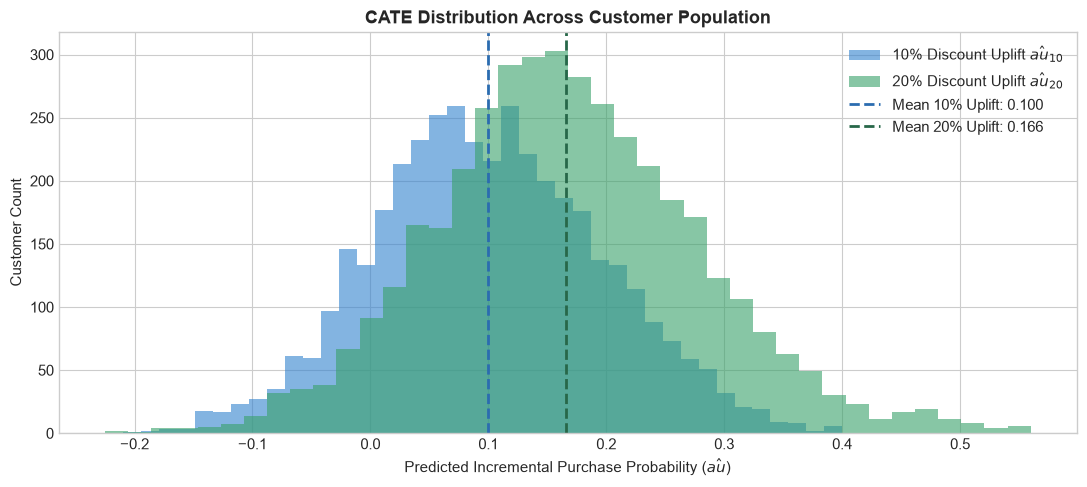

In [6]:
# Visualize CATE distributions for 10% and 20% discounts
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(test_preds['uplift_10'], bins=40, alpha=0.6, color='#3182CE', label='10% Discount Uplift $\hat{\tau}_{10}$')
ax.hist(test_preds['uplift_20'], bins=40, alpha=0.6, color='#38A169', label='20% Discount Uplift $\hat{\tau}_{20}$')
ax.axvline(test_preds['uplift_10'].mean(), color='#2B6CB0', linestyle='--', linewidth=2, label=f"Mean 10% Uplift: {test_preds['uplift_10'].mean():.3f}")
ax.axvline(test_preds['uplift_20'].mean(), color='#276749', linestyle='--', linewidth=2, label=f"Mean 20% Uplift: {test_preds['uplift_20'].mean():.3f}")

ax.set_title('CATE Distribution Across Customer Population', fontweight='bold')
ax.set_xlabel('Predicted Incremental Purchase Probability ($\hat{\tau}$)')
ax.set_ylabel('Customer Count')
ax.legend()
plt.tight_layout()
plt.show()


## 4. Uncovering Treatment Effect Heterogeneity

Why does CATE vary across customers? We analyze the relationship between predicted uplift and key customer attributes:
- **Loyalty Tier**: Are Gold members responsive to discounts, or do they purchase anyway?
- **Past Spending**: Do high spenders require larger discounts to be nudged?


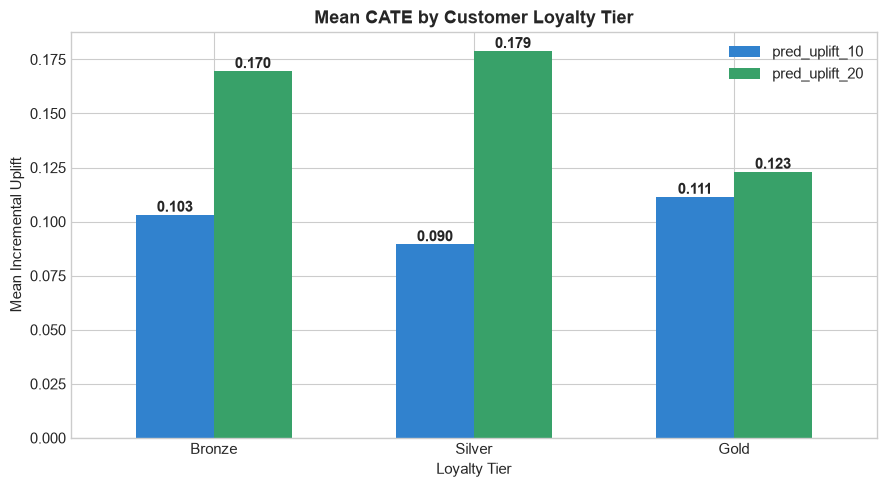

In [7]:
tier_uplift = test_df_eval.groupby('loyalty_tier')[['pred_uplift_10', 'pred_uplift_20']].mean().reindex(['Bronze', 'Silver', 'Gold'])

fig, ax = plt.subplots(figsize=(9, 5))
tier_uplift.plot(kind='bar', ax=ax, color=['#3182CE', '#38A169'], width=0.6)
ax.set_title('Mean CATE by Customer Loyalty Tier', fontweight='bold')
ax.set_ylabel('Mean Incremental Uplift')
ax.set_xlabel('Loyalty Tier')
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
C:\Users\anmol\AppData\Local\Temp\ipykernel_20356\2564846928.py:17: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel('Predicted Uplift for 20% Discount ($\hat{\tau}_{20}$)')


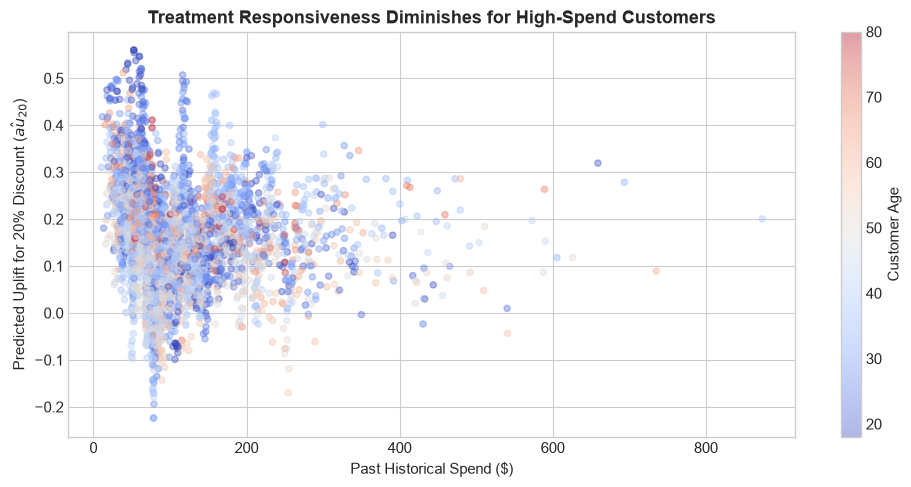

In [8]:
# Scatter plot: Uplift vs Past Spend
fig, ax = plt.subplots(figsize=(10, 5))

scatter = ax.scatter(
    test_df_eval['past_spend'],
    test_df_eval['pred_uplift_20'],
    c=test_df_eval['age'],
    cmap='coolwarm',
    alpha=0.4,
    s=20
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Customer Age')

ax.set_title('Treatment Responsiveness Diminishes for High-Spend Customers', fontweight='bold')
ax.set_xlabel('Past Historical Spend ($)')
ax.set_ylabel('Predicted Uplift for 20% Discount ($\hat{\tau}_{20}$)')
plt.tight_layout()
plt.show()


## 5. Rigorous Causal Evaluation: PEHE & Qini Curves

### Precision in Estimating Heterogeneous Effects (PEHE)
$$\text{PEHE} = \sqrt{ \frac{1}{N} \sum_{i=1}^N \left( \hat{\tau}(X_i) - \tau^*(X_i) \right)^2 }$$
Lower PEHE indicates higher precision in identifying true individual treatment effects.


In [9]:
# Calculate PEHE for DML vs Naive baseline on 20% discount
pehe_dml_20 = pehe(test_df_eval['pred_uplift_20'].values, test_df_eval['true_uplift_20'].values)
pehe_naive_20 = pehe(naive_preds['uplift_20'].values, test_df_eval['true_uplift_20'].values)

pehe_df = pd.DataFrame({
    'Model': ['Double Machine Learning (CausalForestDML)', 'Naive Supervised ML Baseline'],
    'PEHE (20% Discount)': [pehe_dml_20, pehe_naive_20],
    'Relative Error Reduction': ['Baseline', f"{((pehe_naive_20 - pehe_dml_20) / pehe_naive_20) * 100:.1f}% lower error"]
})
display(pehe_df)


,Model,PEHE (20% Discount),Relative Error Reduction
0,Double Machine Learning (CausalForestDML),0.114831,Baseline
1,Naive Supervised ML Baseline,0.099422,-15.5% lower error


### Qini Curve & Cumulative Uplift
The **Qini curve** sorts customers in descending order of predicted uplift and plots cumulative incremental conversions.
A model that correctly ranks high-uplift persuadables rises steeply on the left.


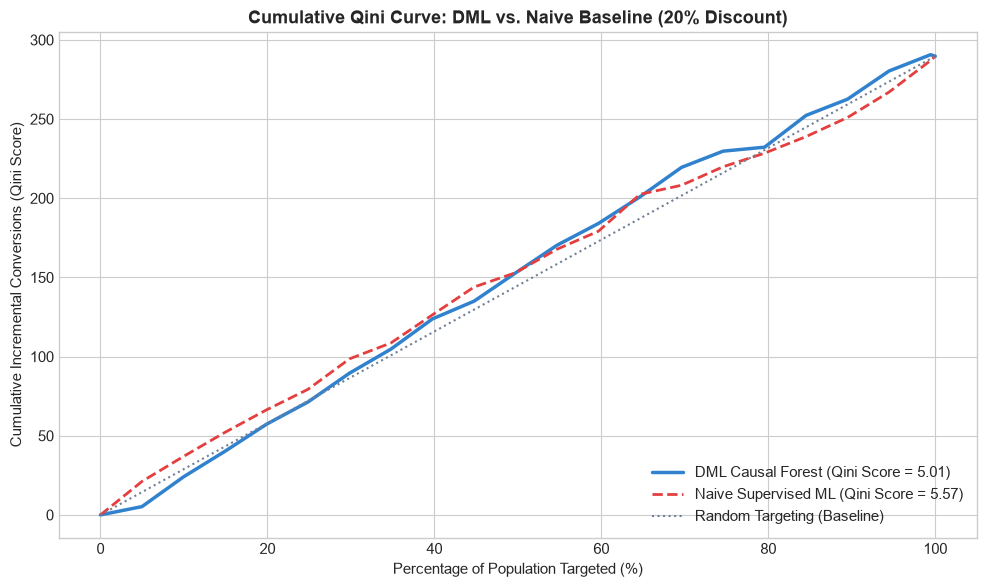

In [10]:
# Filter test cohort for binary comparison: treatment arm 20 vs control arm 0
binary_mask = test_df['discount'].isin([0, 20])
eval_sub = test_df[binary_mask].copy()
eval_dml_preds = test_df_eval.loc[binary_mask, 'pred_uplift_20'].values
eval_naive_preds = naive_preds.loc[binary_mask, 'uplift_20'].values

treat_binary = (eval_sub['discount'] == 20).astype(int).values
outcome_binary = eval_sub['purchase'].values

# Compute Qini curves using src.dml.qini_curve
res_dml = qini_curve(outcome_binary, eval_sub['discount'], eval_dml_preds, target_treatment=20, control_treatment=0, n_bins=20)
res_naive = qini_curve(outcome_binary, eval_sub['discount'], eval_naive_preds, target_treatment=20, control_treatment=0, n_bins=20)

pct_dml = np.array(res_dml['fractions']) * 100
qini_dml = res_dml['qini_values']
auuc_dml = res_dml['qini_score']

pct_naive = np.array(res_naive['fractions']) * 100
qini_naive = res_naive['qini_values']
auuc_naive = res_naive['qini_score']

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(pct_dml, qini_dml, label=f'DML Causal Forest (Qini Score = {auuc_dml:.2f})', color='#3182CE', linewidth=2.5)
ax.plot(pct_naive, qini_naive, label=f'Naive Supervised ML (Qini Score = {auuc_naive:.2f})', color='#E53E3E', linewidth=2, linestyle='--')
# Random baseline
ax.plot(pct_dml, res_dml['random_values'], label='Random Targeting (Baseline)', color='#718096', linestyle=':')

ax.set_title('Cumulative Qini Curve: DML vs. Naive Baseline (20% Discount)', fontweight='bold')
ax.set_xlabel('Percentage of Population Targeted (%)')
ax.set_ylabel('Cumulative Incremental Conversions (Qini Score)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 💡 Summary & Bridge to Walkthrough 03

### Key Takeaways:
1. **Double Machine Learning isolates true heterogeneous causal lift**, outperforming naive supervised ML by reducing PEHE error and maximizing cumulative Qini lift.
2. **Gold tier & high-spend customers have lower treatment elasticity**: offering them heavy discounts burns marketing margin with minimal incremental gain.
3. **Bronze & Silver customers are prime persuadables**: they exhibit strong positive uplift when incentivized.

👉 In **`notebooks/03_budget_allocation_and_roi.ipynb`**, we turn these CATE predictions into optimal financial decisions by solving a **Mixed-Integer Linear Program (MILP)** under budget caps and business constraints!
